# 05 · More Data Can Hurt

**Claim:** hold the model fixed and add training data, and over a whole range the test error gets **worse**. The interpolation threshold is about the *ratio* of parameters to data, and you can walk into the peak from either side.

*Double Descent 101 · notebook 5 of 6 · previous: [04 · Benign overfitting](04_benign_overfitting.ipynb) · next: [06 · What it means for you](06_what_it_means_for_you.ipynb)*

## The experiment

The 20-D random-feature track with the width **fixed** at $p = 100$ features. Only the number of training points $n$ changes, from 10 to 400. Within each draw the training sets are nested: the first 10 points, then the first 20, and so on. Every point added is a genuine extra observation of the same distribution.

Starting with $n < p$, the model is overparameterized. Each new point *removes* slack, pushing the ratio $p/n$ down towards 1, so the model walks straight into the interpolation peak at $n = p$.

In [1]:
import numpy as np
import pandas as pd

from src.config import get_settings
from src.evaluation import aggregate, data_sweep, error_surface, factory_for, task_for
from src.reporting import publish_figure, save_json
from src.visualisation import (
    INK, INK_2, SURFACE, capacity_axes, new_figure, noise_colors, plot_curve, plot_heatmap,
)

settings = get_settings()
SIGMA = settings.headline_noise
M = "random_features"
cfg = settings.data_sweep
P = cfg.n_params
factory, task = factory_for(M, settings), task_for(M, settings)

ds = data_sweep(factory, task, n_params=P, n_train_grid=cfg.n_train_grid, noise_levels=settings.noise_levels,
                n_seeds=cfg.n_seeds, seed=settings.seed)
curves = aggregate(ds, by=("n_train", "noise"))
table = curves.pivot(index="n_train", columns="noise", values="median")
table.round(3).T

n_train,10,20,30,40,50,60,70,80,85,90,...,102,105,110,120,140,160,200,250,300,400
noise,,,,,,,,,,,,,,,,,,,,,
0.0,0.532,0.437,0.378,0.365,0.421,0.476,0.625,0.846,1.082,1.354,...,5.728,2.838,1.426,0.946,0.513,0.361,0.267,0.218,0.195,0.174
0.1,0.542,0.437,0.370,0.394,0.430,0.493,0.671,0.901,1.150,1.519,...,6.287,3.308,1.544,0.904,0.530,0.384,0.275,0.229,0.200,0.178
0.3,0.564,0.505,0.477,0.490,0.563,0.685,0.901,1.295,1.760,2.333,...,10.260,4.970,2.566,1.317,0.748,0.537,0.355,0.290,0.246,0.205
0.5,0.669,0.645,0.696,0.721,0.863,1.052,1.544,2.136,2.918,4.217,...,15.516,8.463,4.571,2.260,1.205,0.811,0.523,0.407,0.337,0.254


σ = 0.3: best n below p = 30 (MSE 0.477); at n = p: 52.91; at n = 400: 0.205


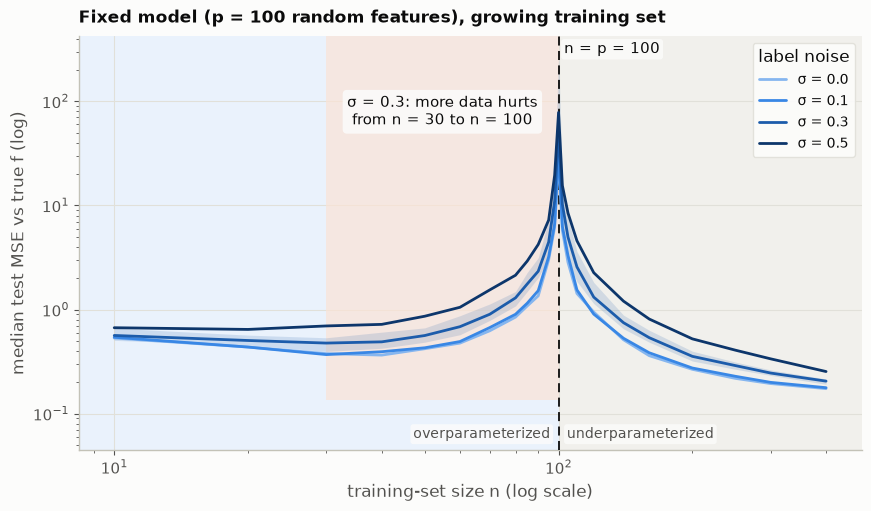

In [2]:
colors = noise_colors(settings.noise_levels)
head = table[SIGMA]
n_best = int(head.loc[: P - 1].idxmin())
fig, (ax,) = new_figure(width=8.6, height=5.0)
ax.axvspan(n_best, P, ymin=0.12, ymax=1.0, color="#fbe3d6", alpha=0.7, lw=0, zorder=1)
for s in settings.noise_levels:
    c = curves[curves["noise"] == s]
    plot_curve(ax, c, colors[s], f"σ = {s}", x="n_train", band=s == SIGMA)
capacity_axes(ax, P, xlabel="training-set size n (log scale)", ylabel="median test MSE vs true f (log)",
              logx=True, threshold_label=f"n = p = {P}", flipped=True)
ax.annotate(f"σ = {SIGMA}: more data hurts\nfrom n = {n_best} to n = {P}", xy=(np.sqrt(n_best * P), 0.86),
            xycoords=("data", "axes fraction"), ha="center", va="top", fontsize=10.5, color=INK,
            bbox={"boxstyle": "round,pad=0.3", "fc": SURFACE, "ec": "none", "alpha": 0.85})
ax.set_title(f"Fixed model (p = {P} random features), growing training set", fontsize=12.5)
ax.legend(loc="upper right", title="label noise", fontsize=10)
publish_figure(
    fig, "05_more_data_hurts", "More data can hurt",
    f"Median test error of min-norm random-feature regression with p = {P} fixed, as the training set grows "
    f"(nested draws, 20-D track). Shaded: the range where adding data makes the σ = {SIGMA} model worse. "
    f"Band: interquartile range at σ = {SIGMA}.",
    {"n_params": P, "n_train": table.index.tolist(), "median_by_noise": {str(s): table[s].tolist() for s in table.columns},
     "hurt_range_at_headline_noise": [n_best, P]},
)
print(f"σ = {SIGMA}: best n below p = {n_best} (MSE {head.loc[n_best]:.3f}); at n = p: {head.loc[P]:.2f}; "
      f"at n = {table.index.max()}: {head.iloc[-1]:.3f}")

At $\sigma = 0.3$ the best training-set size *below* 100 is around 30 points. Every point added after that makes the model worse, until at $n = 100$ the test error is about **a hundred times** higher. Only past $n = p$ does more data start helping again, and by $n = 400$ the error is better than anywhere before. It happens even with no label noise at all: part of the target is beyond what 100 random features can represent, and that misfit plays the role of noise.

This is the same peak as notebooks 02–03, seen from the other axis. Nakkiran et al. (2020) called it *sample-wise* non-monotonicity: for models near the threshold, more data is not unconditionally better.

## One landscape, two slices

Both sweeps are slices of a single error surface over $(p, n)$. The peak is a ridge along the diagonal $p = n$.

median error on the diagonal p = n: min 27.4, max 258.9; best cell: (np.int64(500), np.int64(100)) with 0.185


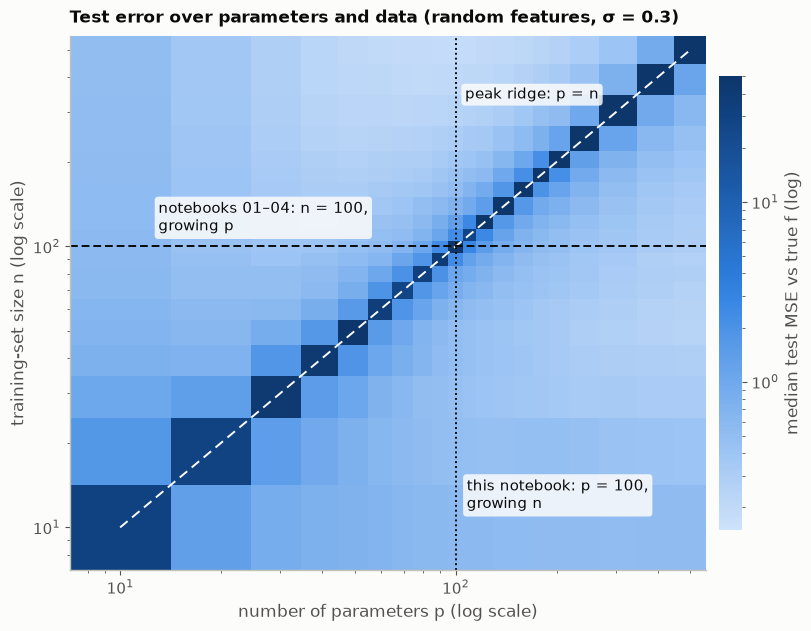

In [3]:
hm = settings.heatmap
surface = error_surface(factory, task, n_params_grid=hm.n_params_grid, n_train_grid=hm.n_train_grid,
                        noise=SIGMA, n_seeds=hm.n_seeds, seed=settings.seed)
grid = surface.groupby(["n_train", "n_params"])["test_mse"].median().unstack("n_params")

fig, (ax,) = new_figure(width=8.0, height=6.2)
mesh = plot_heatmap(ax, grid, vmin=0.15, vmax=50)
cbar = fig.colorbar(mesh, ax=ax, shrink=0.85, pad=0.02)
cbar.set_label("median test MSE vs true f (log)")
cbar.outline.set_visible(False)
ax.axvline(P, color=INK, lw=1.4, ls=(0, (1, 1.5)))
ax.axhline(settings.random_features.n_train, color=INK, lw=1.4, ls=(0, (4, 2)))
ax.annotate(f"this notebook: p = {P},\ngrowing n", xy=(P, 13), xytext=(8, 0), textcoords="offset points",
            fontsize=10.5, color=INK, va="center", bbox={"boxstyle": "round,pad=0.25", "fc": SURFACE, "ec": "none", "alpha": 0.85})
ax.annotate("notebooks 01–04: n = 100,\ngrowing p", xy=(13, settings.random_features.n_train), xytext=(0, 8),
            textcoords="offset points", fontsize=10.5, color=INK, va="bottom",
            bbox={"boxstyle": "round,pad=0.25", "fc": SURFACE, "ec": "none", "alpha": 0.85})
ax.annotate("peak ridge: p = n", xy=(300, 300), xytext=(-12, 10), textcoords="offset points", ha="right",
            fontsize=10.5, color=INK, bbox={"boxstyle": "round,pad=0.25", "fc": SURFACE, "ec": "none", "alpha": 0.85})
ax.set_xlabel("number of parameters p (log scale)")
ax.set_ylabel("training-set size n (log scale)")
ax.set_title(f"Test error over parameters and data (random features, σ = {SIGMA})", fontsize=12.5)
publish_figure(
    fig, "05_error_landscape", "One landscape, two slices",
    f"Median test error over {hm.n_seeds} draws for every (p, n) pair on the 20-D random-feature track, σ = {SIGMA}. "
    "Colour is log-scaled and clipped to [0.15, 50]. The dashed diagonal is p = n; the vertical dotted line is this "
    "notebook's sweep, the horizontal dashed line the capacity sweep of notebooks 01–04.",
    {"noise": SIGMA, "n_params": grid.columns.tolist(), "n_train": grid.index.tolist(), "median_test_mse": grid.to_numpy()},
)
diag = np.diag(grid.to_numpy())
print(f"median error on the diagonal p = n: min {diag.min():.1f}, max {diag.max():.1f}; "
      f"best cell: {grid.stack().idxmin()} with {grid.stack().min():.3f}")

## What you just saw

- **More data can hurt.** With $p = 100$ fixed, going from about 30 to 100 training points makes the test error roughly a hundred times worse, at every noise level, even zero.
- **It is the ratio.** The trouble is $p \approx n$, whichever of the two you change. On the error landscape the peak is a ridge along the diagonal. The capacity sweep (fix $n$, grow $p$) and the data sweep (fix $p$, grow $n$) are two slices across the same ridge.
- **Practical reading:** if a model's size is close to its training-set size, both "add a bit more data" and "add a few more parameters" can move you onto the ridge. Moving well off the diagonal in either direction helps: far more data, or far more parameters.

Notebook 06 turns this into a working framework, including the classical tool that flattens the ridge: regularization.

In [4]:
save_json(
    {
        "notebook": "05_more_data_can_hurt",
        "claim": "At fixed capacity near the threshold, adding training data increases test error over a range; the threshold is about the parameters-to-data ratio.",
        "settings": {"n_params": P, "n_train_grid": cfg.n_train_grid, "noise_levels": settings.noise_levels,
                     "data_sweep_seeds": cfg.n_seeds, "heatmap": hm.model_dump(), "seed": settings.seed},
        "results": {
            "headline_noise": SIGMA,
            "best_n_below_p": n_best,
            "median_test_mse": {"at_best_n_below_p": float(head.loc[n_best]), "at_n_equals_p": float(head.loc[P]),
                                "at_max_n": float(head.iloc[-1])},
            "worsening_factor": float(head.loc[P] / head.loc[n_best]),
            "diagonal_median_range": [float(diag.min()), float(diag.max())],
        },
        "figures": ["05_more_data_hurts", "05_error_landscape"],
        "takeaways": [
            "With p fixed at 100, adding data from about 30 to 100 points makes test error about a hundred times worse.",
            "The peak is a ridge along p = n on the (p, n) error landscape.",
            "Capacity sweeps and data sweeps are two slices across the same ridge.",
        ],
        "next": "06_what_it_means_for_you",
    },
    "05_summary",
)

PosixPath('/workspaces/double_descent_101/outputs/data/05_summary.json')